# 01 · Análise exploratória: homicídios nas capitais brasileiras

**Fonte:** `data/raw/raw_homicidios.csv` (27 capitais, homicídios registrados + ocultos).
Os dados processados são gerados por `python -m crime_analysis process`, que valida o arquivo bruto e grava `reports/validacao_dados.md`.

Roteiro:
1. Qualidade dos dados (o que a validação encontrou)
2. Estatísticas descritivas
3. Distribuição da taxa e diferenças regionais
4. População × taxa
5. Homicídios ocultos (subnotificação)
6. Quartis de risco

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote do projeto sem instalação (ou use `pip install -e .`)
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from crime_analysis import config
from crime_analysis.data import load_processed

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 2)
CORES_REGIAO = {"N": "#2a9d8f", "NE": "#e76f51", "CO": "#e9c46a", "SE": "#264653", "S": "#8ab17d"}

df = load_processed()  # caminho absoluto via config: funciona de qualquer pasta
df.head()

,municipio,uf,regiao,populacao,homicidios_registrados,homicidios_ocultos,homicidios_estimados,taxa_informada_100k,taxa_calculada_100k,taxa_inconsistente,pct_ocultos,log_populacao
0,Porto Velho,RO,N,550463,468,14,482,54.9,87.56,True,2.90,13.22
1,Salvador,BA,NE,2417678,1568,37,1605,66.4,66.39,False,2.31,14.70
2,Recife,PE,NE,1690028,1003,13,1016,45.3,60.12,True,1.28,14.34
3,Manaus,AM,N,2063683,1130,19,1149,55.7,55.68,False,1.65,14.54
4,Macapá,AP,N,442932,241,3,244,55.8,55.09,True,1.23,13.00


## 1. Qualidade dos dados

Antes de qualquer gráfico: a taxa informada na fonte bate com `homicídios estimados ÷ população × 100 mil`?

In [2]:
inconsistentes = df.loc[df["taxa_inconsistente"], ["municipio", "uf", "taxa_informada_100k", "taxa_calculada_100k"]]
inconsistentes = inconsistentes.assign(diferenca=lambda d: d["taxa_informada_100k"] - d["taxa_calculada_100k"])
print(f"{len(inconsistentes)} de {len(df)} capitais têm taxa informada diferente da calculada (> 0,5 ponto).")
inconsistentes.sort_values("diferenca")

9 de 27 capitais têm taxa informada diferente da calculada (> 0,5 ponto).


,municipio,uf,taxa_informada_100k,taxa_calculada_100k,diferenca
0,Porto Velho,RO,54.9,87.56,-32.66
6,São Luís,MA,21.2,39.71,-18.51
8,Natal,RN,22.4,37.39,-14.99
2,Recife,PE,45.3,60.12,-14.82
12,Palmas,TO,21.9,28.41,-6.51
4,Macapá,AP,55.8,55.09,0.71
5,Fortaleza,CE,45.3,44.35,0.95
7,Aracaju,SE,41.8,37.74,4.06
10,Maceió,AL,37.9,31.77,6.13


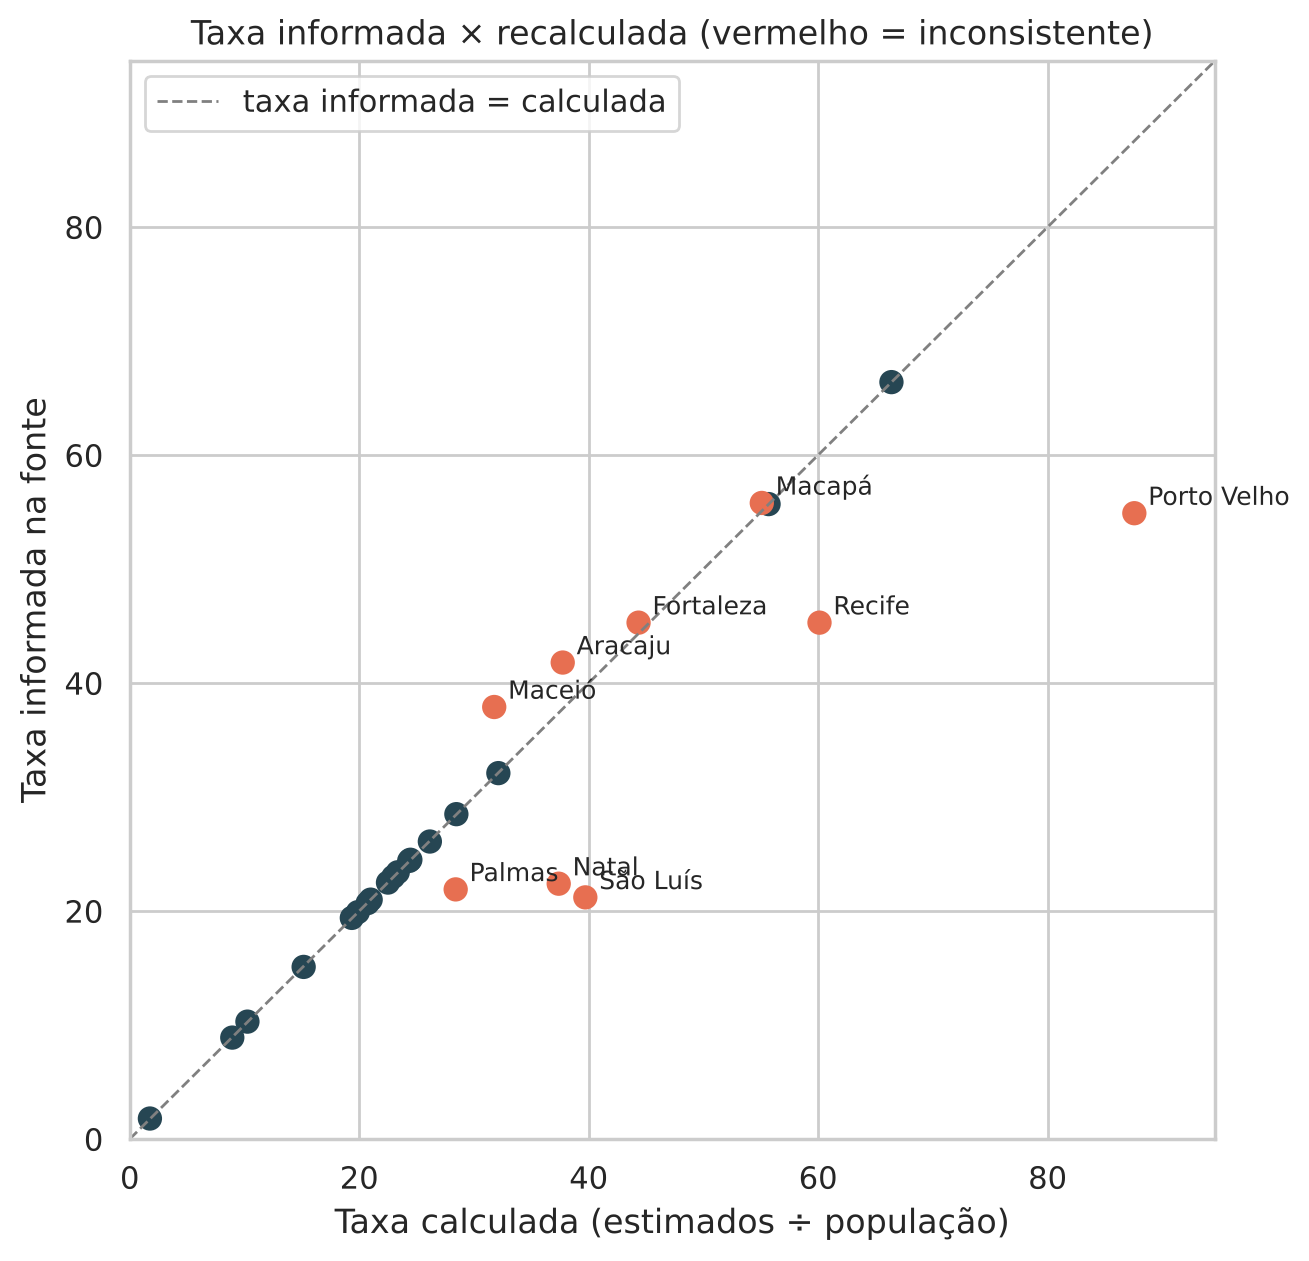

In [3]:
fig, ax = plt.subplots(figsize=(7, 7))
lim = [0, df[["taxa_informada_100k", "taxa_calculada_100k"]].max().max() * 1.08]
ax.plot(lim, lim, ls="--", c="grey", lw=1, label="taxa informada = calculada")
cores = df["taxa_inconsistente"].map({True: "#e76f51", False: "#264653"})
ax.scatter(df["taxa_calculada_100k"], df["taxa_informada_100k"], c=cores, s=60)
for _, r in df[df["taxa_inconsistente"]].iterrows():
    ax.annotate(r["municipio"], (r["taxa_calculada_100k"], r["taxa_informada_100k"]), xytext=(5, 3), textcoords="offset points", fontsize=9)
ax.set(xlim=lim, ylim=lim, xlabel="Taxa calculada (estimados ÷ população)", ylabel="Taxa informada na fonte",
       title="Taxa informada × recalculada (vermelho = inconsistente)")
ax.legend(); plt.show()

**Leitura:** 9 capitais estão fora da diagonal. Em Porto Velho, Recife, Natal e São Luís a diferença passa de 14 pontos, o que muda a posição delas no ranking.
Ou a contagem de homicídios, ou a população, ou a taxa foi copiada errado da fonte.

**Decisão:** daqui em diante usamos `taxa_calculada_100k`, que é coerente com as contagens. A taxa original fica preservada no CSV para conferência.

Outro ponto suspeito: **Brasília com 48 homicídios registrados** (taxa 1,8) é muito abaixo do que se espera para o DF e de qualquer outra capital. Vale conferir na fonte antes de tirar conclusões sobre o Centro-Oeste.

## 2. Estatísticas descritivas

In [4]:
cols = ["populacao", "homicidios_registrados", "homicidios_ocultos", "homicidios_estimados", "taxa_calculada_100k", "pct_ocultos"]
df[cols].describe().T

,count,mean,std,min,25%,50%,75%,max
populacao,27.0,1.83e+06,2.48e+06,302692.00,587038.50,1.03e+06,1.92e+06,1.23e+07
homicidios_registrados,27.0,4.61e+02,4.59e+02,48.00,151.00,3.15e+02,5.32e+02,1.57e+03
homicidios_ocultos,27.0,1.84e+01,3.54e+01,0.00,5.00,8.00e+00,1.35e+01,1.83e+02
homicidios_estimados,27.0,4.79e+02,4.73e+02,48.00,158.50,3.27e+02,5.47e+02,1.60e+03
taxa_calculada_100k,27.0,3.21e+01,1.92e+01,1.76,20.87,2.62e+01,3.87e+01,8.76e+01
pct_ocultos,27.0,4.48e+00,5.49e+00,0.00,1.56,2.61e+00,3.96e+00,2.46e+01


## 3. Distribuição da taxa e diferenças regionais

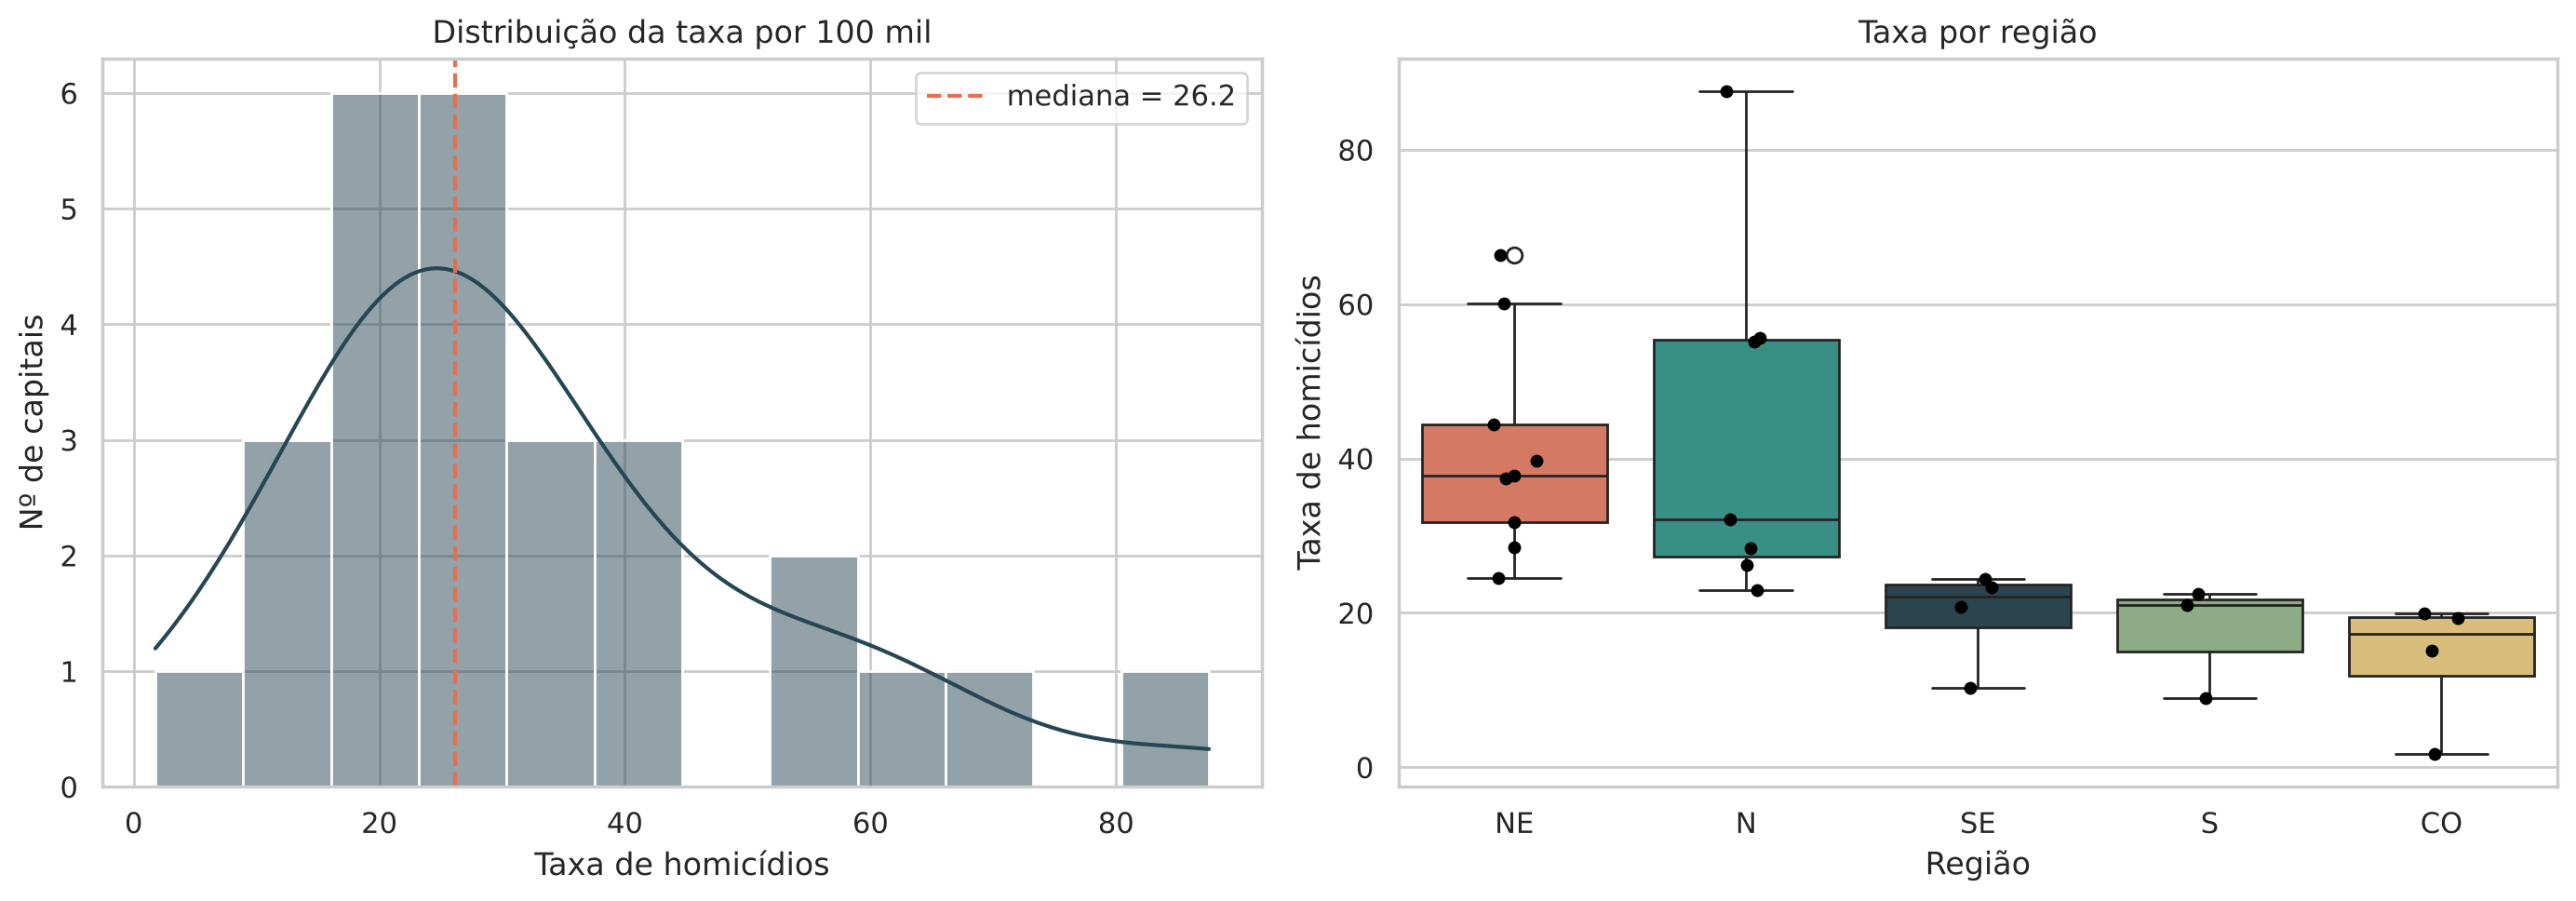

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["taxa_calculada_100k"], bins=12, kde=True, color="#264653", ax=axes[0])
axes[0].axvline(df["taxa_calculada_100k"].median(), c="#e76f51", ls="--", label=f"mediana = {df['taxa_calculada_100k'].median():.1f}")
axes[0].set(title="Distribuição da taxa por 100 mil", xlabel="Taxa de homicídios", ylabel="Nº de capitais"); axes[0].legend()

ordem = df.groupby("regiao")["taxa_calculada_100k"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="regiao", y="taxa_calculada_100k", order=ordem, hue="regiao", palette=CORES_REGIAO, legend=False, ax=axes[1])
sns.stripplot(data=df, x="regiao", y="taxa_calculada_100k", order=ordem, color="black", size=5, ax=axes[1])
axes[1].set(title="Taxa por região", xlabel="Região", ylabel="Taxa de homicídios")
plt.tight_layout(); plt.show()

In [6]:
df.groupby("regiao").agg(
    capitais=("municipio", "count"),
    taxa_mediana=("taxa_calculada_100k", "median"),
    taxa_media=("taxa_calculada_100k", "mean"),
    homicidios=("homicidios_estimados", "sum"),
    populacao=("populacao", "sum"),
).assign(taxa_agregada=lambda d: d["homicidios"] / d["populacao"] * 1e5).sort_values("taxa_mediana", ascending=False)

,capitais,taxa_mediana,taxa_media,homicidios,populacao,taxa_agregada
regiao,,,,,,
NE,9,37.74,41.16,5542,12032266,46.06
N,7,32.13,44.00,2537,5518940,45.97
SE,4,22.05,19.68,3528,21940732,16.08
S,3,21.00,17.48,756,3801479,19.89
CO,4,17.26,14.04,580,6174247,9.39


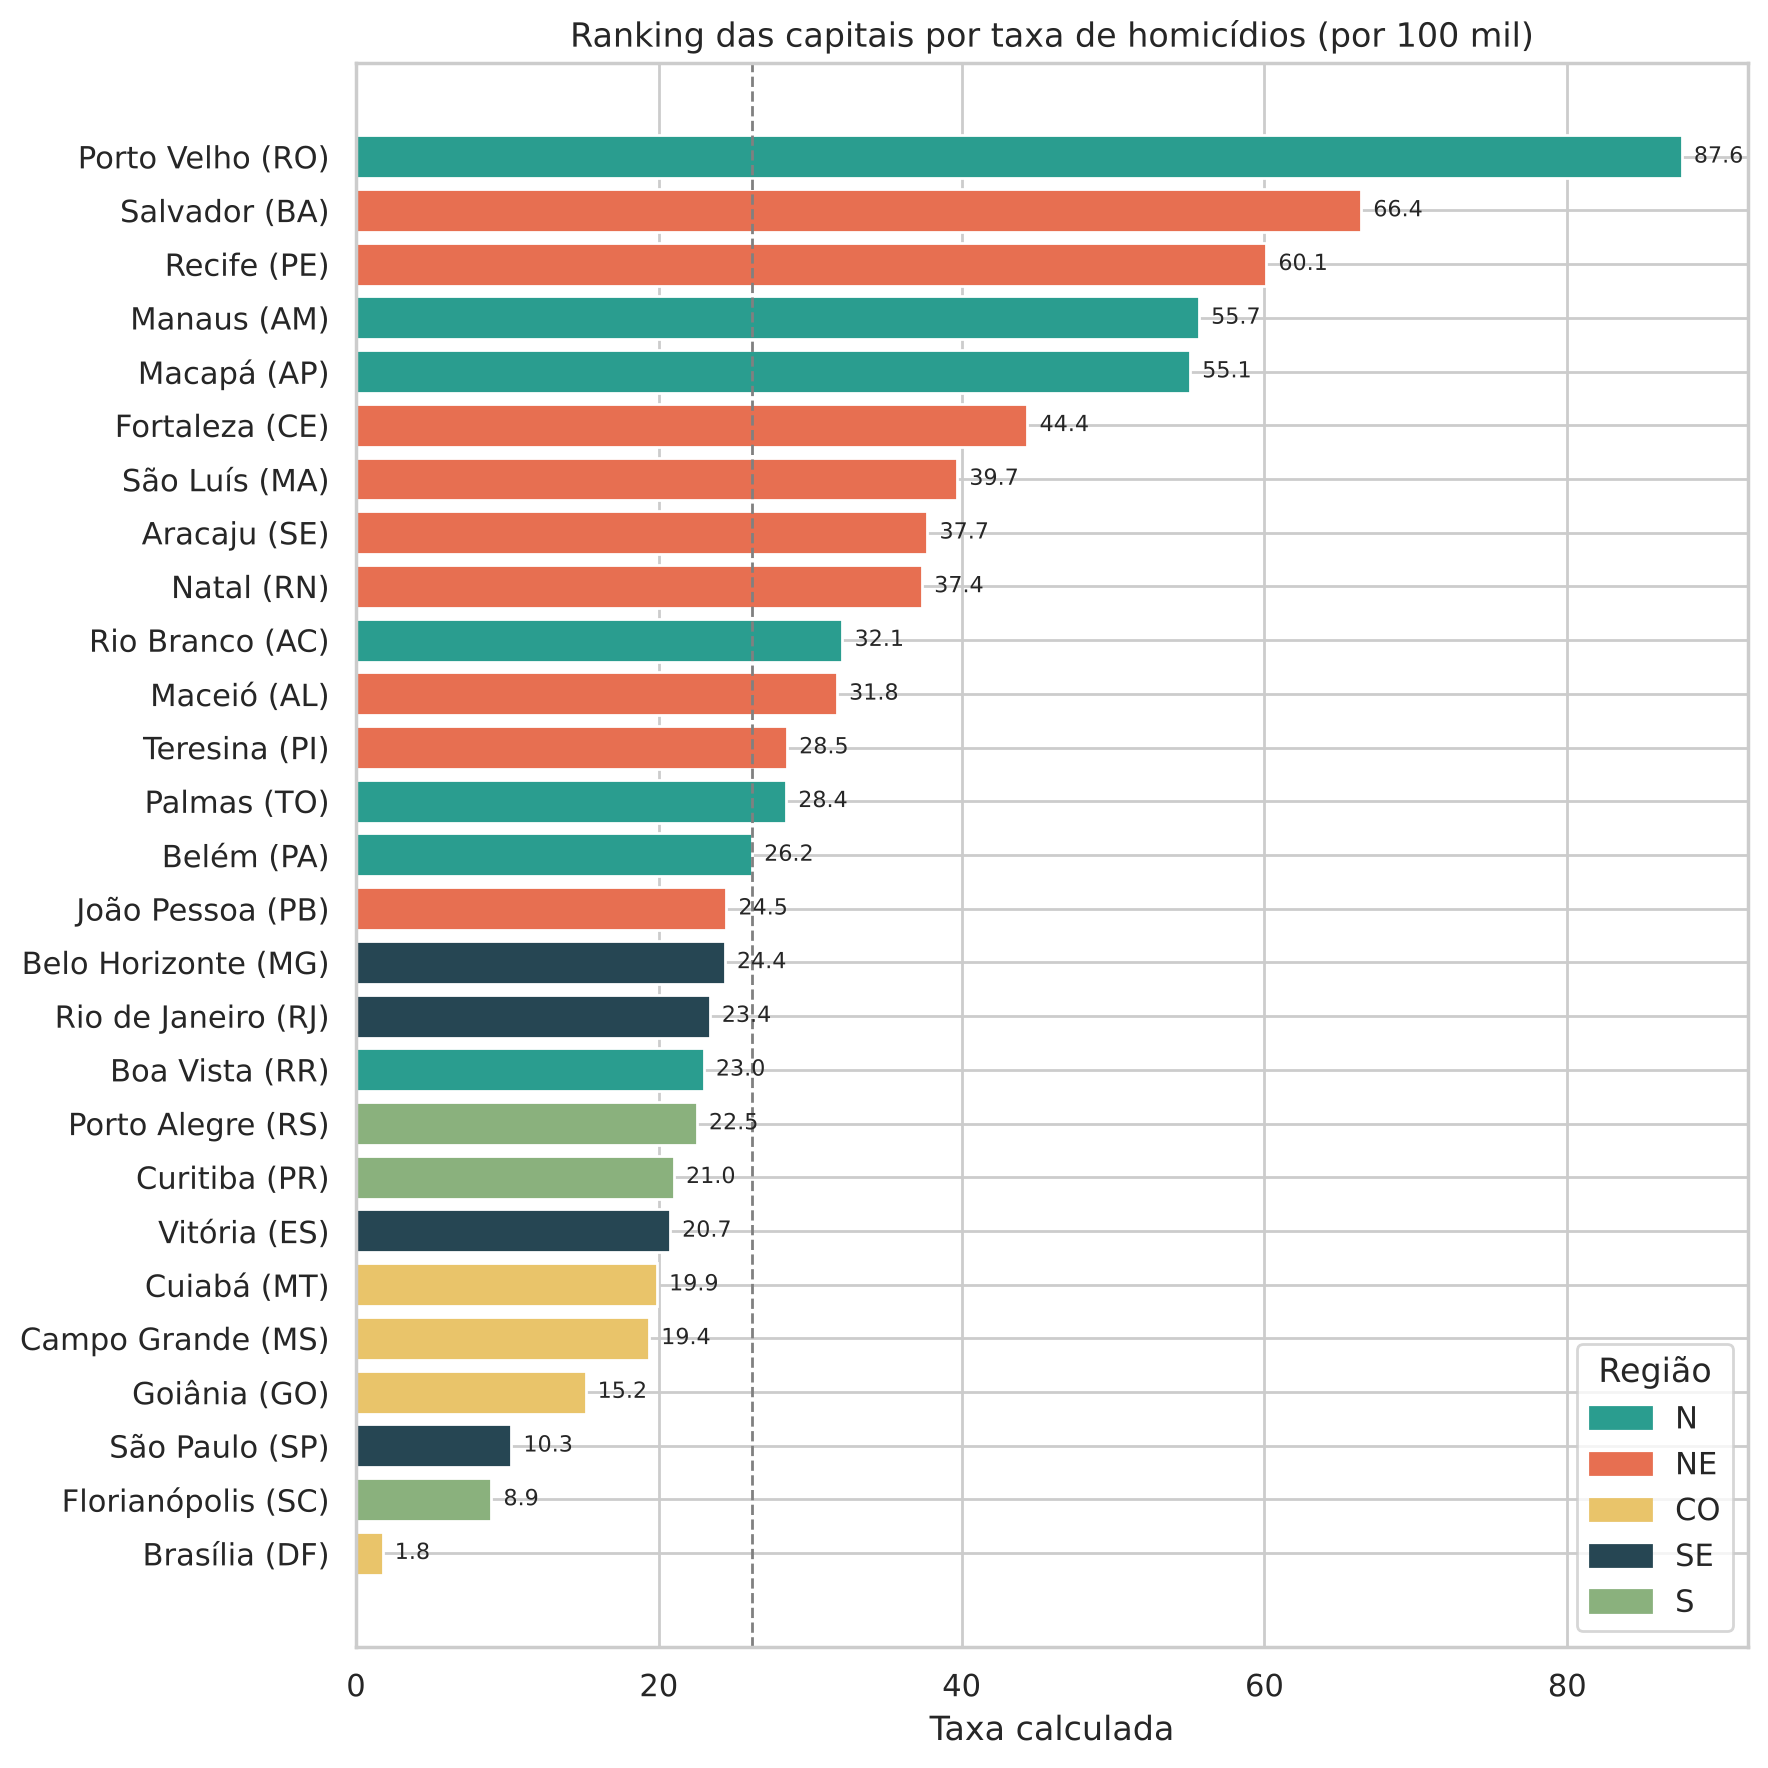

In [7]:
ranking = df.sort_values("taxa_calculada_100k")
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(ranking["municipio"] + " (" + ranking["uf"] + ")", ranking["taxa_calculada_100k"], color=ranking["regiao"].map(CORES_REGIAO))
ax.axvline(df["taxa_calculada_100k"].median(), c="grey", ls="--", lw=1)
for i, v in enumerate(ranking["taxa_calculada_100k"]):
    ax.text(v + 0.8, i, f"{v:.1f}", va="center", fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CORES_REGIAO.values()]
ax.legend(handles, CORES_REGIAO.keys(), title="Região", loc="lower right")
ax.set(title="Ranking das capitais por taxa de homicídios (por 100 mil)", xlabel="Taxa calculada")
plt.tight_layout(); plt.show()

**Leitura:** a distribuição é assimétrica à direita (poucas capitais com taxas muito altas). Norte e Nordeste concentram as maiores taxas; Sul, Sudeste e Centro-Oeste ficam majoritariamente abaixo da mediana.
A região é, de longe, a variável mais informativa disponível neste conjunto.

## 4. População × taxa

O notebook original usava população em escala linear, o que espreme quase todas as capitais à esquerda por causa de São Paulo. Em escala log a relação fica legível.

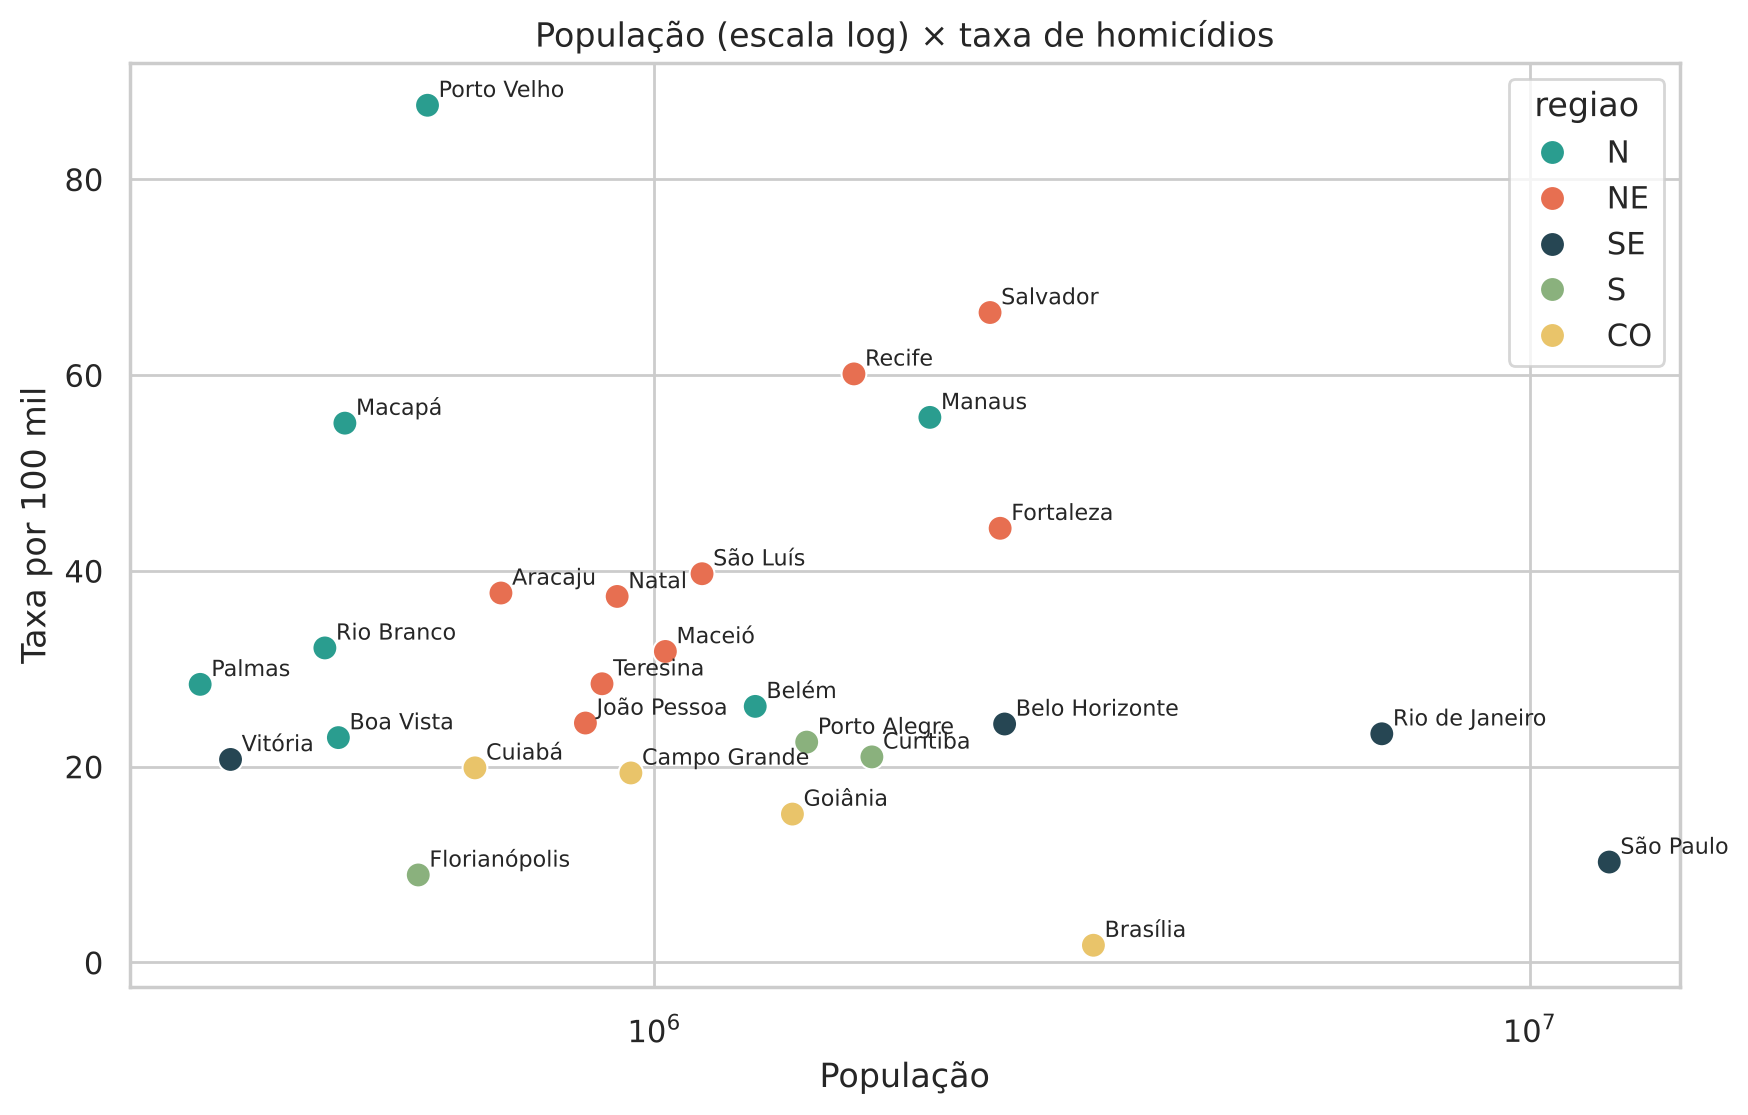

Pearson (log pop × taxa): -0.14 | Spearman (pop × taxa): -0.07


In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="populacao", y="taxa_calculada_100k", hue="regiao", palette=CORES_REGIAO, s=80, ax=ax)
for _, r in df.iterrows():
    ax.annotate(r["municipio"], (r["populacao"], r["taxa_calculada_100k"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set(title="População (escala log) × taxa de homicídios", xlabel="População", ylabel="Taxa por 100 mil")
plt.show()

pearson = df["log_populacao"].corr(df["taxa_calculada_100k"])
spearman = df["populacao"].corr(df["taxa_calculada_100k"], method="spearman")
print(f"Pearson (log pop × taxa): {pearson:.2f} | Spearman (pop × taxa): {spearman:.2f}")

**Leitura:** a correlação é fraca. Tamanho da cidade, sozinho, não explica a taxa — o notebook de modelagem confirma isso: um modelo só com população prevê *pior* que a média simples.

## 5. Homicídios ocultos (subnotificação)

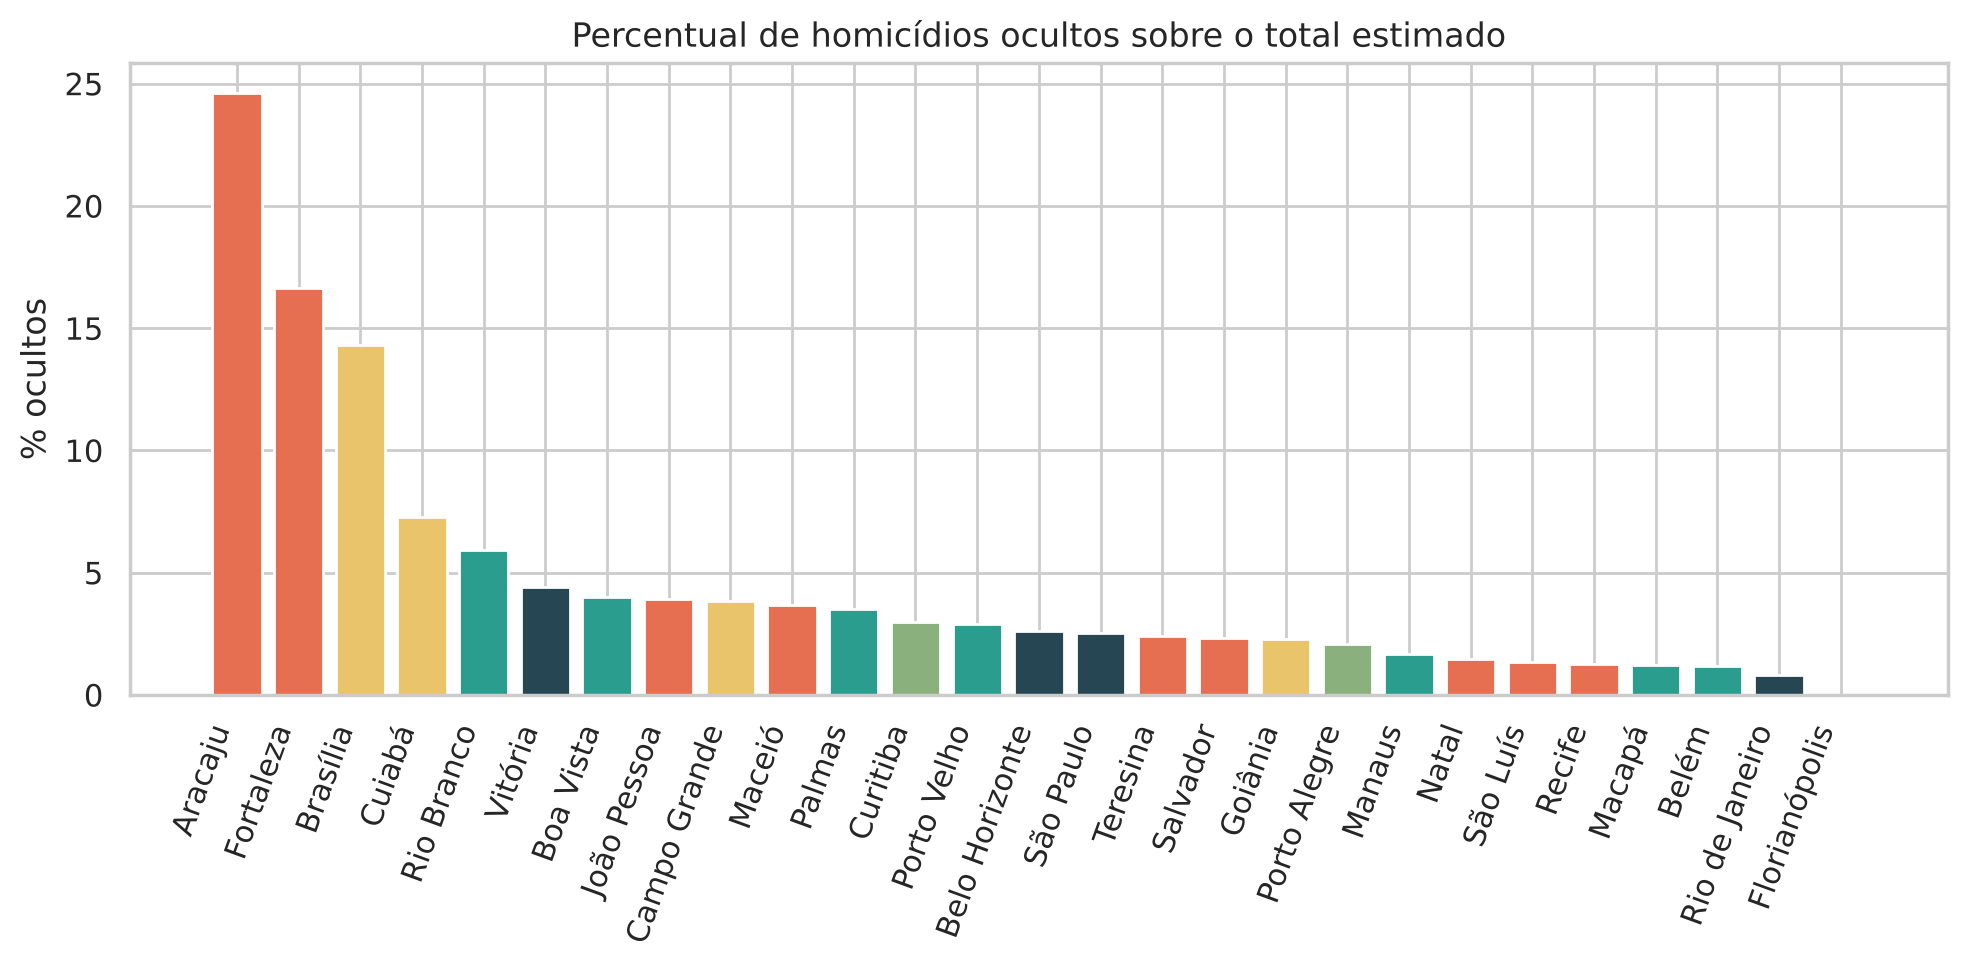

,municipio,uf,homicidios_registrados,homicidios_ocultos,pct_ocultos
7,Aracaju,SE,190,62,24.60
5,Fortaleza,CE,918,183,16.62
26,Brasília,DF,48,8,14.29
21,Cuiabá,MT,115,9,7.26
9,Rio Branco,AC,127,8,5.93


In [9]:
top = df.sort_values("pct_ocultos", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(top["municipio"], top["pct_ocultos"], color=top["regiao"].map(CORES_REGIAO))
ax.set(title="Percentual de homicídios ocultos sobre o total estimado", ylabel="% ocultos")
plt.xticks(rotation=70, ha="right"); plt.tight_layout(); plt.show()
top[["municipio", "uf", "homicidios_registrados", "homicidios_ocultos", "pct_ocultos"]].head(5)

**Leitura:** Aracaju (≈25%) e Fortaleza (≈17%) destoam muito das demais (a maioria abaixo de 5%). Brasília (≈14%) aparece em 3º, mas sobre uma base de apenas 56 homicídios, o que reforça a suspeita sobre esse registro. Nessas capitais, olhar só os registros oficiais subestima bastante a violência — um argumento forte para usar sempre a coluna *estimados*.

## 6. Quartis de risco

In [10]:
df["quartil_risco"] = pd.qcut(df["taxa_calculada_100k"], 4, labels=["Q1 (baixo)", "Q2", "Q3", "Q4 (alto)"])
limites = df.groupby("quartil_risco", observed=True)["taxa_calculada_100k"].agg(["min", "max", "count"])
display(limites)
pd.crosstab(df["regiao"], df["quartil_risco"])

,min,max,count
quartil_risco,,,
Q1 (baixo),1.76,20.74,7
Q2,21.00,26.16,7
Q3,28.41,37.74,6
Q4 (alto),39.71,87.56,7


quartil_risco,Q1 (baixo),Q2,Q3,Q4 (alto)
regiao,,,,
CO,4,0,0,0
N,0,2,2,3
NE,0,1,4,4
S,1,2,0,0
SE,2,2,0,0


## Conclusões

- **Os dados precisam de revisão na fonte:** 9 de 27 taxas não batem com as contagens, e Brasília parece subestimada.
- **Região domina:** as 7 capitais do quartil de maior risco são todas do Norte ou Nordeste; todas as capitais do Sul, Sudeste e Centro-Oeste estão abaixo da mediana.
- **População explica pouco:** a correlação com a taxa é fraca.
- **Subnotificação é desigual:** em Aracaju e Fortaleza uma fração grande dos homicídios é oculta.
- **Limitação central:** 27 observações de um único ano e nenhuma variável socioeconômica. Ver `SUGESTOES.md` para os próximos passos.

Próximo: `02_modelagem.ipynb`.